
# 01 · Exploración y calidad de los datos — NYC 311

Antes de pensar en modelos quiero entender con qué datos cuento: si están completos, si son confiables y cómo se comporta la demanda semanal en cada borough de Nueva York. Este notebook recoge lo que revisé y lo que decidí a partir de cada hallazgo.

- **Pregunta de negocio:** ¿qué nivel de demanda (bajo, medio o alto) de solicitudes no urgentes se espera la próxima semana en cada borough?
- **Fuente:** NYC Open Data, dataset 311 Service Requests (`erm2-nwe9`), consultado por API para 2022-2025.
- **Datos de entrada:** `data/raw/nyc311_diario_borough_tipo.parquet`, con una fila por día, borough y tipo de queja (`n` es el número de solicitudes).


## 0. Configuración

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# Detecta la raíz del repo: funciona si Jupyter corre desde la raíz o desde notebooks/
RAIZ = Path.cwd()
if not (RAIZ / "data").exists() and (RAIZ.parent / "data").exists():
    RAIZ = RAIZ.parent

RUTA = RAIZ / "data" / "raw" / "nyc311_diario_borough_tipo.parquet"
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Cifras de referencia de la validación previa (validar_nyc_api.py)
ESPERADO_TOTAL = 13_506_495
ESPERADO_ANIO = {2022: 3_169_960, 2023: 3_224_723, 2024: 3_456_770, 2025: 3_655_042}
ESPERADO_DIAS = 1461  # 2022-01-01 a 2025-12-31

print("Raíz del repo:", RAIZ)
print("Archivo existe:", RUTA.exists())

Raíz del repo: /tmp/claude-0/real
Archivo existe: True


## 1. Carga y estructura

In [2]:
df = pd.read_parquet(RUTA)
df["dia"] = pd.to_datetime(df["dia"])

print("Forma:", df.shape)
print(df.dtypes, "\n")
print(df.head())
print("\nMemoria: %.1f MB" % (df.memory_usage(deep=True).sum() / 1e6))

Forma: (652633, 4)
borough                      str
dia               datetime64[us]
complaint_type               str
n                          int64
dtype: object 

  borough        dia             complaint_type  n
0   BRONX 2022-01-01          Abandoned Vehicle  3
1   BRONX 2022-01-01               Animal-Abuse  2
2   BRONX 2022-01-01           Animal in a Park  1
3   BRONX 2022-01-01                  APPLIANCE  5
4   BRONX 2022-01-01  Bike/Roller/Skate Chronic  1

Memoria: 36.8 MB


**Qué encontré.** La tabla tiene 652.633 filas y cuatro columnas (`borough`, `dia`, `complaint_type` y `n`). Cada fila resume cuántas solicitudes de un tipo hubo en un borough en un día, y ocupa unos 37 MB en memoria, así que se maneja sin problema en un computador normal.

## 2. Calidad: nulos, duplicados y valores inválidos

In [3]:
clave = ["borough", "dia", "complaint_type"]

calidad = pd.Series({
    "filas": len(df),
    "nulos (total celdas)": int(df.isna().sum().sum()),
    "duplicados por clave": int(df.duplicated(clave).sum()),
    "n <= 0": int((df["n"] <= 0).sum()),
    "n no entero": int((df["n"] % 1 != 0).sum()),
    "borough vacío": int((df["borough"].str.strip() == "").sum()),
    "complaint_type vacío": int((df["complaint_type"].str.strip() == "").sum()),
})
print(calidad.to_string())

total = int(df["n"].sum())
print(f"\nSolicitudes totales: {total:,}  |  esperado: {ESPERADO_TOTAL:,}  |  coincide: {total == ESPERADO_TOTAL}")

por_anio = df.groupby(df["dia"].dt.year)["n"].sum()
comp = pd.DataFrame({"obtenido": por_anio, "esperado": pd.Series(ESPERADO_ANIO)})
comp["coincide"] = comp["obtenido"] == comp["esperado"]
print("\n", comp)

filas                   652633
nulos (total celdas)         0
duplicados por clave         0
n <= 0                       0
n no entero                  0
borough vacío                0
complaint_type vacío         0

Solicitudes totales: 13,506,495  |  esperado: 13,506,495  |  coincide: True

       obtenido  esperado  coincide
2022   3169960   3169960      True
2023   3224723   3224723      True
2024   3456770   3456770      True
2025   3655042   3655042      True


**Qué encontré.** No hay nulos, duplicados por (borough, día, tipo), conteos menores o iguales a cero ni textos vacíos. Además, el total de 13.506.495 solicitudes y los totales de 2022, 2023, 2024 y 2025 coinciden exactamente con lo que había consultado antes al API, por lo que la descarga está completa y puedo confiar en ella.

## 3. Boroughs

               solicitudes    pct
borough                          
BROOKLYN           4050080  29.99
QUEENS             3211390  23.78
BRONX              2936122  21.74
MANHATTAN          2775156  20.55
STATEN ISLAND       518683   3.84
Unspecified          15064   0.11


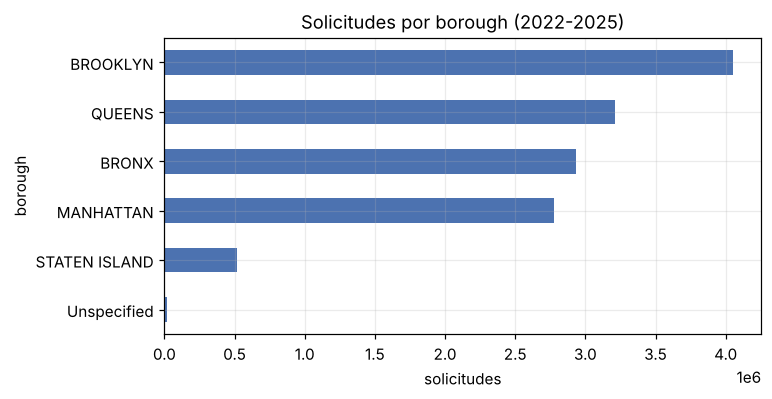

In [4]:
b = df.groupby("borough")["n"].sum().sort_values(ascending=False)
tabla_b = pd.DataFrame({"solicitudes": b, "pct": (b / b.sum() * 100).round(2)})
print(tabla_b)

fig, ax = plt.subplots(figsize=(7, 3.5))
tabla_b["solicitudes"].plot.barh(ax=ax, color="#4c72b0")
ax.invert_yaxis(); ax.set_title("Solicitudes por borough (2022-2025)"); ax.set_xlabel("solicitudes")
fig.savefig(FIG / "boroughs.png", bbox_inches="tight"); plt.show()

**Qué encontré.** Los boroughs son muy desiguales: Brooklyn concentra casi el 30% de las solicitudes y Queens el 23,8%, mientras que Staten Island solo tiene el 3,8%. Esto significa que un "nivel alto" en Brooklyn no se parece en nada a uno en Staten Island, así que los niveles de demanda tienen que calcularse dentro de cada borough. Las solicitudes sin borough (`Unspecified`) son el 0,11%, un porcentaje tan pequeño que las voy a excluir.

## 4. Cobertura temporal

In [5]:
rango = pd.date_range("2022-01-01", "2025-12-31")
dias_datos = df["dia"].drop_duplicates()
faltantes = rango.difference(dias_datos)

print("Rango en datos:", df["dia"].min().date(), "->", df["dia"].max().date())
print(f"Días con datos: {dias_datos.nunique()} (esperados: {ESPERADO_DIAS})")
print("Días faltantes:", len(faltantes), list(faltantes[:10].date))

# Combinaciones día-borough ausentes (solo boroughs principales)
principales = [x for x in df["borough"].unique() if x != "Unspecified"]
for bo in principales:
    nd = df.loc[df["borough"] == bo, "dia"].nunique()
    print(f"  {bo:<14} {nd} días ({ESPERADO_DIAS - nd} sin registros)")

mensual = df.groupby(df["dia"].dt.to_period("M"))["n"].sum()
print("\nMeses con datos:", len(mensual), "(esperados: 48)")

Rango en datos: 2022-01-01 -> 2025-12-31
Días con datos: 1461 (esperados: 1461)
Días faltantes: 0 []
  BRONX          1461 días (0 sin registros)
  BROOKLYN       1461 días (0 sin registros)
  MANHATTAN      1461 días (0 sin registros)
  QUEENS         1461 días (0 sin registros)
  STATEN ISLAND  1461 días (0 sin registros)

Meses con datos: 48 (esperados: 48)


**Qué encontré.** Hay datos para los 1.461 días entre el 1 de enero de 2022 y el 31 de diciembre de 2025, en los cinco boroughs y sin huecos, y los 48 meses del periodo están completos. Como la serie no tiene faltantes, no necesito imputar nada antes de agregar por semana.

## 5. Tipos de queja y consistencia de nombres

Tipos distintos: 239
Tipos tras normalizar (minúsculas y espacios): 224
Top 10 = 54.7% de las solicitudes
Tipos con menos de 1.000 solicitudes: 98



Familias de queja: 213
familia
noise                   3012350
illegal parking         1965737
heat/hot water          1076409
blocked driveway         665217
unsanitary condition     454553
street condition         284706
plumbing                 268194
abandoned vehicle        265652
water system             259994
paint/plaster            236791
dirty condition          212268
derelict vehicles        191680
Name: n, dtype: int64

Familia Noise:
complaint_type
Noise - Residential         1518147
Noise - Street/Sidewalk      636557
Noise - Commercial           261197
Noise                        211753
Noise - Vehicle              208013
Noise - Helicopter           134585
Noise - Park                  34980
Noise - House of Worship       7118
Name: n, dtype: int64


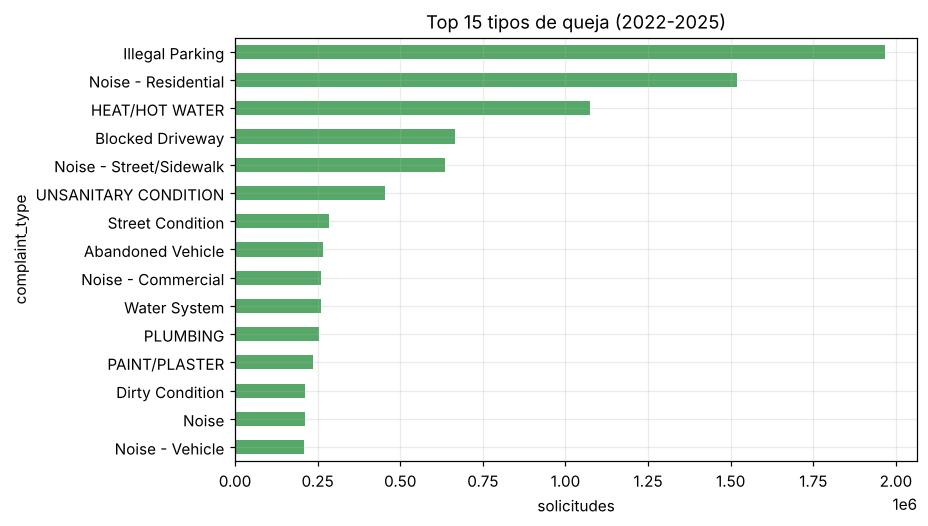

In [6]:
tipos = df.groupby("complaint_type")["n"].sum().sort_values(ascending=False)
norm = df["complaint_type"].str.strip().str.lower()

print("Tipos distintos:", len(tipos))
print("Tipos tras normalizar (minúsculas y espacios):", norm.nunique())
print("Top 10 = %.1f%% de las solicitudes" % (tipos.head(10).sum() / tipos.sum() * 100))
print("Tipos con menos de 1.000 solicitudes:", int((tipos < 1000).sum()))

# Familias por prefijo (p. ej. 'Noise - Residential' -> 'noise')
familia = (norm.str.split(" - ").str[0].str.strip())
fam = df.assign(familia=familia).groupby("familia")["n"].sum().sort_values(ascending=False)
print("\nFamilias de queja:", len(fam))
print(fam.head(12))

print("\nFamilia Noise:")
print(tipos[tipos.index.str.contains("noise", case=False)])

fig, ax = plt.subplots(figsize=(8, 5))
tipos.head(15).iloc[::-1].plot.barh(ax=ax, color="#55a868")
ax.set_title("Top 15 tipos de queja (2022-2025)"); ax.set_xlabel("solicitudes")
fig.savefig(FIG / "top_tipos_queja.png", bbox_inches="tight"); plt.show()

**Qué encontré.** Hay 239 tipos de queja, pero bajan a 224 al pasar todo a minúsculas, porque algunos vienen escritos de dos maneras (por ejemplo `APPLIANCE` y `Appliance`). Los diez tipos más frecuentes suman el 54,7% de las solicitudes, mientras que 98 tipos tienen menos de mil solicitudes en cuatro años. La familia del ruido es la más grande, con unos 3 millones de solicitudes (cerca del 22% del total), pero mezcla cosas distintas: ruido residencial, de calle, comercial, de helicópteros y de parques. Antes de decidir qué cuenta como "no urgente" tengo que revisar con el equipo si todos estos subtipos se comportan igual.

## 6. Serie semanal por borough

Semanas completas: 208 (esperadas: 208) | parciales descartadas: 2
Filas semana-borough: 1040 (esperadas: 1.040)
Semanas por borough:
 borough
BRONX            208
BROOKLYN         208
MANHATTAN        208
QUEENS           208
STATEN ISLAND    208
Name: semana, dtype: int64


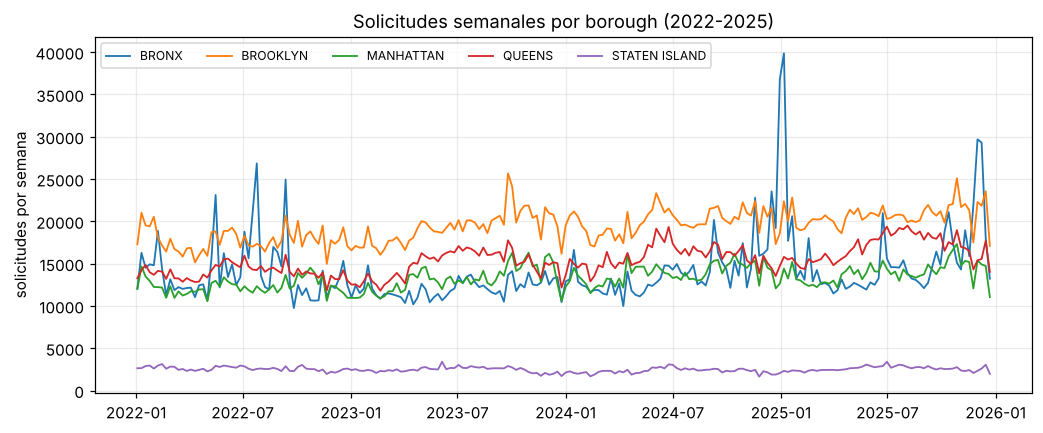

In [7]:
d = df[df["borough"] != "Unspecified"].copy()
d["semana"] = d["dia"].dt.to_period("W-SUN").dt.start_time

# Semana completa = lunes a domingo dentro del rango de fechas (criterio por calendario)
ini, fin = df["dia"].min(), df["dia"].max()
semanas = d["semana"].drop_duplicates().sort_values()
completas = semanas[(semanas >= ini) & (semanas + pd.Timedelta(days=6) <= fin)]
print(f"Semanas completas: {len(completas)} (esperadas: 208) | parciales descartadas: {len(semanas) - len(completas)}")

sem = (d[d["semana"].isin(completas)]
       .groupby(["semana", "borough"], as_index=False)["n"].sum())

print("Filas semana-borough:", len(sem), "(esperadas: 1.040)")
print("Semanas por borough:\n", sem.groupby("borough")["semana"].nunique())

fig, ax = plt.subplots(figsize=(11, 4.2))
for bo, g in sem.groupby("borough"):
    ax.plot(g["semana"], g["n"], label=bo, lw=1.2)
ax.set_title("Solicitudes semanales por borough (2022-2025)")
ax.set_ylabel("solicitudes por semana"); ax.legend(ncol=5, fontsize=8, loc="upper left")
fig.savefig(FIG / "serie_semanal_borough.png", bbox_inches="tight"); plt.show()

**Qué encontré.** Al agrupar por semana (de lunes a domingo) quedan 208 semanas completas por borough, es decir, 1.040 observaciones, y descarté las dos semanas parciales de los extremos del periodo. Esta es la tabla con la que voy a entrenar el modelo, y es pequeña, así que más adelante tendré que cuidar el sobreajuste. En la gráfica se ve que Brooklyn y Queens están en la parte alta y que Staten Island se mantiene muy por debajo, y también que el Bronx tiene picos mucho más bruscos que los demás.

## 7. Tendencia anual

Promedio semanal por año y borough:
 borough    BRONX  BROOKLYN  MANHATTAN   QUEENS  STATEN ISLAND
anio                                                         
2022     14091.0   17770.0    12314.0  13999.0         2592.0
2023     12050.0   19212.0    13156.0  14903.0         2459.0
2024     14441.0   19971.0    13805.0  15800.0         2313.0
2025     15745.0   20710.0    13935.0  16883.0         2585.0

Crecimiento total vs 2022:
anio
2022     0.0 %
2023     1.7 %
2024    11.3 %
2025    12.8 %
Name: n, dtype: str

Crecimiento 2025 vs 2022 por borough (%):
 borough
BRONX            11.7
BROOKLYN         16.5
MANHATTAN        13.2
QUEENS           20.6
STATEN ISLAND    -0.3
dtype: float64


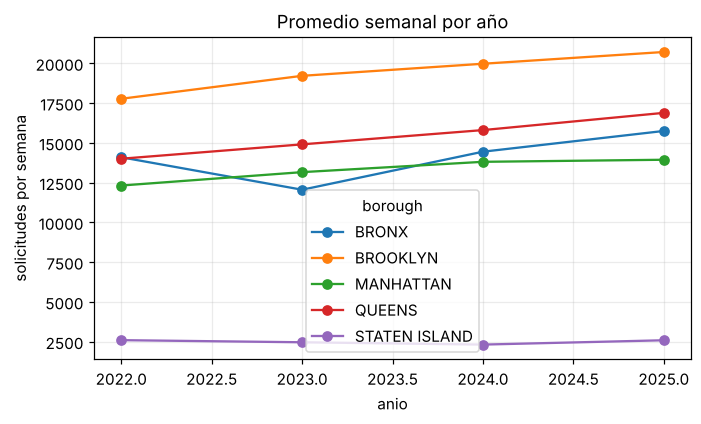

In [8]:
sem["anio"] = sem["semana"].dt.year
prom = sem.groupby(["anio", "borough"])["n"].mean().unstack().round(0)
print("Promedio semanal por año y borough:\n", prom)

tot_anio = sem.groupby("anio")["n"].sum()
print("\nCrecimiento total vs 2022:")
print(((tot_anio / tot_anio.iloc[0] - 1) * 100).round(1).astype(str) + " %")

crec = ((prom.loc[2025] / prom.loc[2022] - 1) * 100).round(1)
print("\nCrecimiento 2025 vs 2022 por borough (%):\n", crec)

fig, ax = plt.subplots(figsize=(7, 3.8))
prom.plot(ax=ax, marker="o")
ax.set_title("Promedio semanal por año"); ax.set_ylabel("solicitudes por semana")
fig.savefig(FIG / "tendencia_anual.png", bbox_inches="tight"); plt.show()

**Qué encontré.** La demanda total creció 12,8% entre 2022 y 2025, pero ese crecimiento no es parejo. Queens subió 20,6%, Brooklyn 16,5%, Manhattan 13,2% y el Bronx 11,7%, mientras que Staten Island quedó prácticamente igual (-0,3%). El 2023 se ve raro: el total solo creció 1,7% porque el Bronx bajó ese año (de unas 14.000 a unas 12.000 solicitudes por semana). Por todo esto no puedo usar umbrales fijos para definir bajo, medio y alto, porque casi todas las semanas de 2025 quedarían en "alto". La idea es definir los niveles dentro de cada borough y comparando cada semana con su promedio de las últimas 52 semanas.

## 8. Estacionalidad

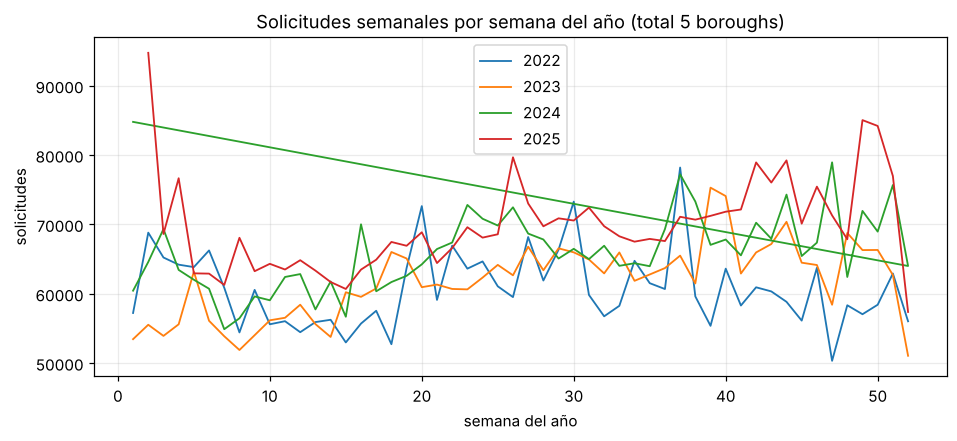

Índice mensual (1,0 = promedio del año):
 anio   2022   2023   2024   2025
mes                             
1     1.057  0.901  0.997  1.143
2     0.925  0.837  0.835  0.838
3     0.954  0.937  0.926  0.923
4     0.894  0.921  0.929  0.895
5     1.047  1.045  0.986  0.969
6     1.029  0.994  1.063  1.006
7     1.115  1.077  1.038  1.037
8     1.019  1.052  0.989  0.998
9     1.030  1.055  1.065  0.994
10    1.011  1.127  1.065  1.105
11    0.933  1.042  1.019  1.001
12    0.987  1.011  1.090  1.090


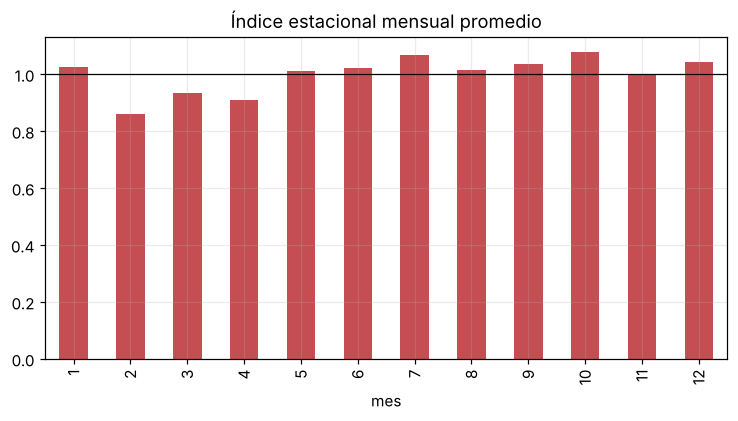

In [9]:
tot = sem.groupby("semana", as_index=False)["n"].sum()
tot["anio"] = tot["semana"].dt.year
tot["sem_anio"] = tot["semana"].dt.isocalendar().week.astype(int).clip(upper=52)

fig, ax = plt.subplots(figsize=(10, 4))
for a, g in tot.groupby("anio"):
    ax.plot(g["sem_anio"], g["n"], label=str(a), lw=1.2)
ax.set_title("Solicitudes semanales por semana del año (total 5 boroughs)")
ax.set_xlabel("semana del año"); ax.set_ylabel("solicitudes"); ax.legend()
fig.savefig(FIG / "estacionalidad_semana_anio.png", bbox_inches="tight"); plt.show()

# Índice mensual: mes / promedio del año (quita la tendencia)
m = df.groupby([df["dia"].dt.year.rename("anio"), df["dia"].dt.month.rename("mes")])["n"].sum().unstack(0)
indice = (m / m.mean()).round(3)
print("Índice mensual (1,0 = promedio del año):\n", indice)

fig, ax = plt.subplots(figsize=(8, 3.8))
indice.mean(axis=1).plot.bar(ax=ax, color="#c44e52")
ax.axhline(1, color="k", lw=.8); ax.set_title("Índice estacional mensual promedio"); ax.set_xlabel("mes")
fig.savefig(FIG / "indice_estacional.png", bbox_inches="tight"); plt.show()

**Qué encontré.** Hay algo de estacionalidad, aunque no muy fuerte. Julio y octubre suelen estar por encima del promedio del año (índices entre 1,01 y 1,13) y febrero siempre queda por debajo (entre 0,84 y 0,93). Enero, en cambio, cambia mucho de un año a otro (0,90 en 2023 y 1,14 en 2025), así que no me sirve como patrón estable. Aun así, el mes y la semana del año me parecen buenas variables para el modelo.

## 9. Valores atípicos

In [10]:
def z_robusto(x):
    med = x.rolling(13, center=True, min_periods=5).median()
    res = x - med
    mad = (res - res.median()).abs().median() * 1.4826
    return res / mad

sem = sem.sort_values(["borough", "semana"])
sem["z"] = sem.groupby("borough")["n"].transform(z_robusto)

atip = sem[sem["z"].abs() > 3].sort_values("z", key=abs, ascending=False)
print("Semanas con |z robusto| > 3:", len(atip))
print(atip.head(15)[["semana", "borough", "n", "z"]].round({"z": 2}).to_string(index=False))

top_meses = df.groupby(df["dia"].dt.to_period("M"))["n"].sum().sort_values(ascending=False).head(3)
print("\nMeses más altos:\n", top_meses)

Semanas con |z robusto| > 3: 69
    semana   borough     n     z
2025-01-06     BRONX 39863 18.47
2024-12-30     BRONX 36794 15.91
2022-09-12     BRONX 24934 10.38
2022-07-25     BRONX 26835  9.94
2025-12-01     BRONX 29681  9.93
2025-12-08     BRONX 29306  9.45
2022-05-16     BRONX 23111  8.79
2023-09-25  BROOKLYN 25672  6.89
2025-12-22 MANHATTAN 11044 -6.23
2025-12-22  BROOKLYN 17104 -6.18
2025-06-23     BRONX 20974  5.92
2025-11-24  BROOKLYN 17488 -5.79
2023-12-25    QUEENS 12157 -5.73
2023-12-25  BROOKLYN 16161 -5.70
2024-11-18     BRONX 22779  5.51

Meses más altos:
 dia
2025-01    348180
2025-10    336612
2025-12    332103
Freq: M, Name: n, dtype: int64


**Qué encontré.** Comparando cada semana con la mediana de sus semanas vecinas, 69 de las 1.040 observaciones se alejan de forma importante (|z| > 3), y las más extremas casi todas son del Bronx. La más marcada es la semana del 6 de enero de 2025, con un z robusto de 18,5, muy lejos de lo habitual para ese borough. Hay también semanas muy bajas en Navidad y a fin de año en varios boroughs. No voy a eliminar estas semanas sin entender qué pasó: primero las reviso en detalle en las siguientes secciones.

In [11]:

tot_sem = sem.groupby("semana")["n"].sum().sort_values()
print("Las 6 semanas con menos solicitudes (total de los 5 boroughs):")
print(tot_sem.head(6))


Las 6 semanas con menos solicitudes (total de los 5 boroughs):
semana
2022-11-21    50332
2023-12-25    51061
2023-02-20    51894
2022-05-02    52728
2022-04-11    52983
2023-01-02    53457
Name: n, dtype: int64



**Qué encontré.** Las semanas más bajas de toda la serie coinciden con feriados en cuatro de las seis: la semana de Acción de Gracias de 2022 (21 de noviembre), la de Navidad de 2023 (25 de diciembre), la de Presidents' Day de 2023 (20 de febrero) y la de Año Nuevo de 2023 (2 de enero). Esto me dice que una variable de feriado puede ayudar al modelo a explicar caídas que no tienen que ver con la demanda "normal".


### 9.1 Enero de 2025 (mes más alto de la serie)

In [12]:
def mes(anio, m):
    x = df[(df["dia"].dt.year == anio) & (df["dia"].dt.month == m)]
    return x

e24, e25 = mes(2024, 1), mes(2025, 1)
print(f"Enero 2024: {e24['n'].sum():,} | Enero 2025: {e25['n'].sum():,} | variación: {(e25['n'].sum()/e24['n'].sum()-1)*100:.1f}%")

dif = (e25.groupby("complaint_type")["n"].sum()
       .sub(e24.groupby("complaint_type")["n"].sum(), fill_value=0)
       .sort_values(ascending=False))
print("\nTipos que más aumentaron (ene 2025 - ene 2024):")
print(dif.head(8).astype(int))

print("\nPor borough:")
print((e25.groupby("borough")["n"].sum() - e24.groupby("borough")["n"].sum()).astype(int))

diario = e25.groupby("dia")["n"].sum()
print("\nDías más altos de enero 2025:")
print(diario.sort_values(ascending=False).head(5).astype(int))

Enero 2024: 287,186 | Enero 2025: 348,180 | variación: 21.2%

Tipos que más aumentaron (ene 2025 - ene 2024):
complaint_type
Noise - Residential    48746
HEAT/HOT WATER         15904
Water System            2759
Illegal Parking         2015
Snow or Ice             1922
Missed Collection        698
PLUMBING                 609
Panhandling              571
Name: n, dtype: int64

Por borough:
borough
BRONX            53656
BROOKLYN          1815
MANHATTAN         1873
QUEENS            3009
STATEN ISLAND      657
Unspecified        -16
Name: n, dtype: int64

Días más altos de enero 2025:
dia
2025-01-07    15023
2025-01-09    14906
2025-01-10    14220
2025-01-06    14141
2025-01-02    13811
Name: n, dtype: int64


**Qué encontré.** Enero de 2025 es el mes con más solicitudes de toda la serie (348.180), un 21,2% más que enero de 2024. Casi todo ese aumento viene del Bronx (+53.656 solicitudes, frente a cambios de entre 650 y 3.000 en los demás boroughs), y por tipo lo explican sobre todo el ruido residencial (+48.746) y la calefacción (+15.904). No hay un solo día extremo: los días más altos de enero están entre 13.800 y 15.000 solicitudes, así que el aumento fue sostenido durante el mes. Con estos datos no puedo saber la causa, y por eso lo voy a tratar como un comportamiento atípico y no como una tendencia.

### 9.2 El ruido residencial en el Bronx

Mediana mensual: 7,972

Meses más altos:
dia
2025-01    52688
2025-12    37472
2022-07    31541
2024-12    28249
2025-10    25986
2022-09    24688
Freq: M, Name: n, dtype: int64

Total por año en el Bronx:
dia
2022    161592
2023     75418
2024    143171
2025    209381
Name: n, dtype: int64


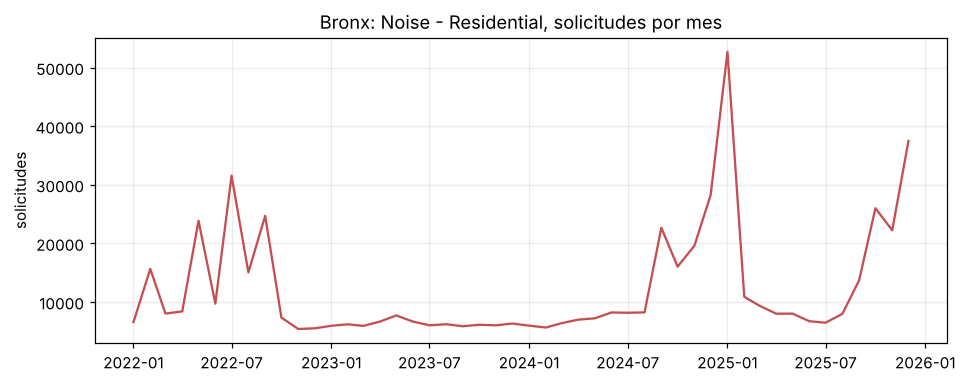

In [13]:

bx = df[(df["borough"] == "BRONX") & (df["complaint_type"] == "Noise - Residential")]
mensual_bx = bx.groupby(bx["dia"].dt.to_period("M"))["n"].sum()

print("Mediana mensual:", f"{int(mensual_bx.median()):,}")
print("\nMeses más altos:")
print(mensual_bx.sort_values(ascending=False).head(6))

print("\nTotal por año en el Bronx:")
print(bx.groupby(bx["dia"].dt.year)["n"].sum())

fig, ax = plt.subplots(figsize=(10, 3.6))
mensual_bx.index = mensual_bx.index.to_timestamp()
ax.plot(mensual_bx.index, mensual_bx.values, color="#c44e52")
ax.set_title("Bronx: Noise - Residential, solicitudes por mes")
ax.set_ylabel("solicitudes")
fig.savefig(FIG / "bronx_ruido_residencial.png", bbox_inches="tight"); plt.show()



**Qué encontré.** El ruido residencial del Bronx es muy inestable: su mediana mensual es de unas 8.000 solicitudes, pero llegó a 52.688 en enero de 2025, 37.472 en diciembre de 2025 y 31.541 en julio de 2022. También explica la caída del Bronx en 2023, porque ese año tuvo menos de la mitad de las solicitudes de este tipo que en 2022 (75.418 frente a 161.592). Este tipo de queja es el que más mueve la serie del Bronx y puede contaminar la etiqueta de demanda si lo incluyo como "no urgente". Mi plan es entrenar el modelo con y sin `Noise - Residential` y comparar los resultados.


## 10. Candidatos a solicitudes "no urgentes"

In [14]:
cand = tipos.head(40).reset_index()
cand.columns = ["complaint_type", "solicitudes"]
cand["pct"] = (cand["solicitudes"] / tipos.sum() * 100).round(2)
cand["pct_acum"] = cand["pct"].cumsum().round(1)
cand["no_urgente"] = ""   # <- el equipo completa: SI / NO / DUDA
print(cand.to_string(index=False))

cand.to_csv(RAIZ / "reports" / "candidatos_no_urgentes.csv", index=False)
print("\nGuardado: reports/candidatos_no_urgentes.csv")

               complaint_type  solicitudes   pct  pct_acum no_urgente
              Illegal Parking      1965737 14.55      14.6           
          Noise - Residential      1518147 11.24      25.8           
               HEAT/HOT WATER      1074595  7.96      33.8           
             Blocked Driveway       665217  4.93      38.7           
      Noise - Street/Sidewalk       636557  4.71      43.4           
         UNSANITARY CONDITION       453290  3.36      46.8           
             Street Condition       284706  2.11      48.9           
            Abandoned Vehicle       265652  1.97      50.8           
           Noise - Commercial       261197  1.93      52.8           
                 Water System       259994  1.92      54.7           
                     PLUMBING       254346  1.88      56.6           
                PAINT/PLASTER       234604  1.74      58.3           
              Dirty Condition       212268  1.57      59.9           
                    

**Decisión del equipo (obligatoria):** 311 no trae un campo de urgencia. Completa la columna `no_urgente` del CSV (SI / NO / DUDA), con el criterio y quién lo aprobó. Propuesta inicial para discutir:

- **Candidatos a no urgentes:** `Illegal Parking`, `Blocked Driveway`, `Abandoned Vehicle`, `Derelict Vehicles`, `Dirty Condition`, `Missed Collection` y la familia `Noise`.
- **Dudosos (afectan habitabilidad):** `HEAT/HOT WATER`, `WATER LEAK`, `PLUMBING`, `UNSANITARY CONDITION`.
- **Sensibles:** `Encampment`, `Homeless Person Assistance`.

## 11. Resumen de hallazgos y decisiones

In [15]:
tot_total = int(df["n"].sum())
unspec = df.loc[df["borough"] == "Unspecified", "n"].sum()
crec_total = (tot_anio.iloc[-1] / tot_anio.iloc[0] - 1) * 100

resumen = pd.DataFrame([
    ("Nulos / duplicados / n<=0", f"{int(df.isna().sum().sum())} / {int(df.duplicated(clave).sum())} / {int((df['n']<=0).sum())}", "Sin acción si son 0"),
    ("Total de solicitudes", f"{tot_total:,}", "Coincide con la validación" if tot_total == ESPERADO_TOTAL else "REVISAR: no coincide"),
    ("Días con datos", f"{dias_datos.nunique()} de {ESPERADO_DIAS}", "Documentar faltantes"),
    ("Borough Unspecified", f"{unspec:,} ({unspec/tot_total*100:.2f}%)", "Excluir de la serie semanal"),
    ("Tipos de queja", f"{len(tipos)} (tras normalizar: {norm.nunique()})", "Normalizar y agrupar por familia"),
    ("Semanas completas", f"{len(completas)}", "Descartar semanas parciales"),
    ("Crecimiento 2022 → 2025", f"{crec_total:.1f}%", "Niveles relativos a promedio móvil 52 semanas"),
    ("Semanas atípicas (|z|>3)", f"{len(atip)}", "Revisar y documentar; no eliminar sin causa"),
    ("Regla de no urgentes", "Pendiente", "Equipo define y justifica"),
], columns=["hallazgo", "valor", "decisión"])
print(resumen.to_string(index=False))
resumen.to_csv(RAIZ / "reports" / "resumen_calidad.csv", index=False)

                 hallazgo                      valor                                      decisión
Nulos / duplicados / n<=0                  0 / 0 / 0                           Sin acción si son 0
     Total de solicitudes                 13,506,495                    Coincide con la validación
           Días con datos               1461 de 1461                          Documentar faltantes
      Borough Unspecified             15,064 (0.11%)                   Excluir de la serie semanal
           Tipos de queja 239 (tras normalizar: 224)              Normalizar y agrupar por familia
        Semanas completas                        208                   Descartar semanas parciales
  Crecimiento 2022 → 2025                      12.8% Niveles relativos a promedio móvil 52 semanas
 Semanas atípicas (|z|>3)                         69   Revisar y documentar; no eliminar sin causa
     Regla de no urgentes                  Pendiente                     Equipo define y justifica



## Conclusión

Los datos están completos y limpios, y alcanzan para construir el modelo: son 1.040 observaciones semanales por borough. Lo que más cuidado me pide es cómo defino la etiqueta de demanda, por tres razones: la demanda crece distinto en cada borough, el Bronx tiene picos muy fuertes que vienen del ruido residencial, y los feriados bajan la demanda de forma puntual. Lo que sigue es acordar con el equipo la lista de solicitudes "no urgentes" (columna `no_urgente` de `reports/candidatos_no_urgentes.csv`) y pasar estas decisiones a `src/limpieza.py`.
